In [ ]:
from google.colab import userdata
token = userdata.get('GITHUB_TOKEN')

REPO = "smart-waste-multi-agent"

%cd /content
!git clone https://{token}@github.com/Nafila1234/{REPO}.git
%cd /content/{REPO}
!git config user.name "Nafila1234"
!git config user.email "nafiladziri17@gmail.com"

/content
Cloning into 'smart-waste-multi-agent'...
remote: Enumerating objects: 50, done.
remote: Counting objects: 100% (50/50), done.
remote: Compressing objects: 100% (33/33), done.
remote: Total 50 (delta 13), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (50/50), 53.68 KiB | 1.92 MiB/s, done.
Resolving deltas: 100% (13/13), done.
/content/smart-waste-multi-agent


In [11]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/{REPO}
!git pull

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/smart-waste-multi-agent
Already up to date.


In [8]:
!mkdir -p /content/garbage
!unzip -q "/content/archive (1).zip" -d /content/garbage

In [9]:
!ls /content/garbage

battery  glass	metal  organic	paper  plastic


In [10]:
!rm -rf /content/DM-Project

In [12]:
%cd /content/{REPO}

/content/smart-waste-multi-agent


Explore the images : find the folder that contains the class folders

In [13]:
import os, glob, random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

# find the folder that directly contains the 'battery' folder
DATA_DIR = None
for root, dirs, files in os.walk("/content/garbage"):
    if "battery" in dirs:
        DATA_DIR = root
        break
print("DATA_DIR:", DATA_DIR)

classes = sorted(d for d in os.listdir(DATA_DIR)
                 if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Classes:", classes)

sizes = []
for c in classes:
    files = glob.glob(os.path.join(DATA_DIR, c, "*"))
    print(f"{c:10s} {len(files)} images")
    for p in random.sample(files, 20):
        sizes.append(Image.open(p).size)
print("Example image sizes:", sizes[:10])

DATA_DIR: /content/garbage
Classes: ['battery', 'glass', 'metal', 'organic', 'paper', 'plastic']
battery    775 images
glass      775 images
metal      775 images
organic    775 images
paper      775 images
plastic    775 images
Example image sizes: [(225, 225), (220, 165), (225, 225), (250, 202), (445, 113), (228, 221), (225, 225), (225, 225), (259, 195), (300, 168)]


show one photo per class:

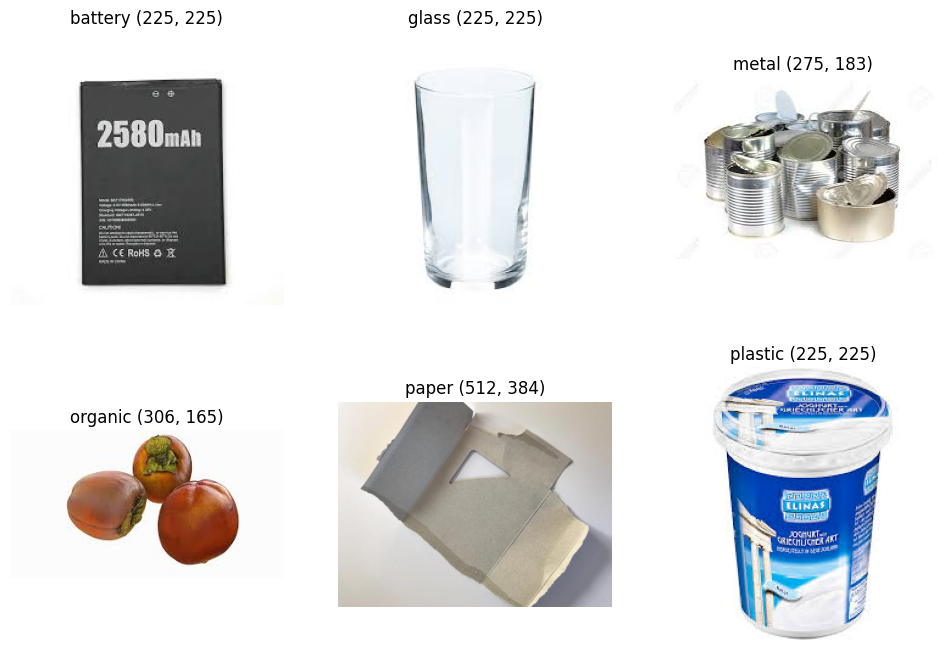

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, c in zip(axes.flatten(), classes):
    p = random.choice(glob.glob(os.path.join(DATA_DIR, c, "*")))
    img = Image.open(p)
    ax.imshow(img)
    ax.set_title(f"{c} {img.size}")
    ax.axis("off")
plt.show()

Save to GitHub

In [ ]:
%cd /content/{REPO}
!git pull
!cp "/content/drive/MyDrive/Colab Notebooks/01_explore_garbage_images.ipynb" visual_agent/
!git add .
!git commit
